Import delle librerie

In [ ]:
import os
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torchvision.models import resnet18
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
from PIL import Image
from torch.utils.data import random_split
from google.colab import drive
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score

Configurazione Google Drive

In [ ]:
drive.mount("/content/drive")

# Percorso dataset
path_dataset = '/content/drive/My Drive/Colab Notebooks/Datasets/project work computer vision/bottle/'

# Controllo se il percorso esiste
if not (os.path.exists(path_dataset)):
    print("Errore nel percorso del dataset!")
else:
    print("Dataset trovato!")

Mounted at /content/drive
Dataset trovato!


Controllo se è disponibile una GPU

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Caricamento del dataset

In [ ]:
class MVTECDataset(Dataset):
  def __init__(self, root_dir, split, transform=None):
    self.split = split.lower()
    self.transform = transform

    # Percorsi delle immagini in base allo split scelto
    self.image_paths = []
    if self.split == "train":
      # Se lo split è 'train' -> carico le immagini dal percorso root_dir/train/good
      img_dir = os.path.join(root_dir, "train", "good")
      for file in os.listdir(img_dir):
        if file.lower().endswith((".png", ".jpg", ".jpeg")):
          self.image_paths.append(os.path.join(img_dir, file))
    elif self.split == "test":
      # Se lo split è test carico tutte le immagini contenute nelle cartelle di root_dir/test
      test_dir = os.path.join(root_dir, "test")
      for subfolder in os.listdir(test_dir):
        subfolder_path = os.path.join(test_dir, subfolder)
        if os.path.isdir(subfolder_path):
          for file in os.listdir(subfolder_path):
            if file.lower().endswith((".png", ".jpg", ".jpeg")):
              self.image_paths.append(os.path.join(subfolder_path, file))
    else:
      # Uso errato della classe
      raise ValueError("split deve essere 'train' o 'test'")

  def __len__(self):
    return len(self.image_paths)

  def __getitem__(self, index):
    # Caricamento dell'immagine e applicazione delle trasformazioni
    img_path = self.image_paths[index]
    image = Image.open(img_path).convert("RGB")
    if self.transform:
      image = self.transform(image)

      # Definizione dell'etichetta:
      # Per il training/validation sono tutte immagini corrette -> etichetta 0
      # Per il test, se il path contiene la cartella "good" l'immagine viene considerata corretta -> 0, altrimenti anomala -> 1
      label = 0
      if self.split == "test":
        if "good" not in os.path.normpath(img_path).split(os.sep):
          label = 1

    return {"image": image, "label": label}

# Definizione delle trasformazioni: ridimensionamento a 128x128, conversione in tensore e normalizzazione in [-1,1].
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Creazione dei DataLoader
dataset_train = MVTECDataset(root_dir=path_dataset, split="train", transform=transform)
dataloader_train = DataLoader(dataset_train, batch_size=16, shuffle=True, num_workers=2)

# Creazione validation set
val_ratio = 0.2
n_train = len(dataset_train)
n_val = int(val_ratio * n_train)
n_train = n_train - n_val
dataset_train, dataset_val = random_split(dataset_train, [n_train, n_val])
dataloader_val = DataLoader(dataset_val, batch_size=16, shuffle=False, num_workers=2)


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Definizione della rete

In [ ]:
# Definizione Encoder
class Encoder(nn.Module):
  def __init__(self, latent_dim=512):
    super(Encoder, self).__init__()
    # ResNet18 pre addestrata
    resnet = resnet18(pretrained=True)
    # Mantengo tutti i layer tranne gli ultimi due (avgpool e fc)
    self.features = nn.Sequential(*list(resnet.children())[:-2])
    # Congelo tutti i layer inizialmente
    for param in self.features.parameters():
      param.requires_grad = False

    # Sblocco solo gli ultimi strati (da layer3 in poi) -> fine tuning
    for child in list(self.features.children())[-3:]:
      for param in child.parameters():
        param.requires_grad = True
    # Il latent_dim corrisponde al numero di canali in uscita (ResNet18 -> 512)

  def forward(self, x):
    z = self.features(x)  # Output atteso: (batch-size, 512, 4, 4) per immagini 128x128
    return z

# Definizione Decoder
class Decoder(nn.Module):
  def __init__(self, latent_dim=512):
    super(Decoder, self).__init__()
    self.decoder = nn.Sequential(
      # (512,4,4) -> (256,8,8)
      nn.ConvTranspose2d(latent_dim, 256, kernel_size=4, stride=2, padding=1),
      nn.BatchNorm2d(256),
      nn.LeakyReLU(0.2),
      # (256,8,8) -> (128,16,16)
      nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
      nn.BatchNorm2d(128),
      nn.LeakyReLU(0.2),
      # (128,16,16) -> (64,32,32)
      nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
      nn.BatchNorm2d(64),
      nn.LeakyReLU(0.2),
      # (64,32,32) -> (32,64,64)
      nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
      nn.BatchNorm2d(32),
      nn.LeakyReLU(0.2),
      # (32,64,64) -> (3,128,128)
      nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
      nn.Tanh()  # Output nell'intervallo [-1, 1] come l'immagine originale dopo le trasformazioni
  )

  def forward(self, z):
    x_hat = self.decoder(z)
    return x_hat
# Nuovo discriminatore
class Discriminatore(nn.Module):
  def __init__(self):
    super(Discriminatore, self).__init__()
    self.disc = nn.Sequential(
      # Input: (3,128,128) -> (32,64,64)
      nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
      nn.LeakyReLU(0.2),
      nn.Dropout2d(0.25),

      # (32,64,64) -> (64,32,32)
      nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
      nn.BatchNorm2d(64),
      nn.LeakyReLU(0.2),
      nn.Dropout2d(0.25),

      # (64,32,32) -> (128,16,16)
      nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
      nn.BatchNorm2d(128),
      nn.LeakyReLU(0.2),
      nn.Dropout2d(0.25),

      # (128,16,16) -> (256,8,8)
      nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
      nn.BatchNorm2d(256),
      nn.LeakyReLU(0.2),
      nn.Dropout2d(0.25),

      # (256,8,8) -> (512,4,4)
      nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1),
      nn.BatchNorm2d(512),
      nn.LeakyReLU(0.2),
      nn.Dropout2d(0.25)
    )
    # Layer fully connected per ottenere il punteggio finale
    self.fc = nn.Sequential(
      nn.Flatten(),
      nn.Linear(512 * 4 * 4, 1),
      nn.Sigmoid()  # Output in [0,1]
    )

  def forward(self, x):
    features = self.disc(x)
    validity = self.fc(features)
    return validity

class GANomaly(nn.Module):
  def __init__(self, device='cuda', latent_dim=512):
    super(GANomaly, self).__init__()
    self.device = device
    self.encoder = Encoder(latent_dim=latent_dim).to(device)        # Primo encoder per l'immagine originale
    self.encoder_hat = Encoder(latent_dim=latent_dim).to(device)    # Secondo encoder per l'immagine ricostruita (non condivide i pesi con il primo)
    self.decoder = Decoder(latent_dim=latent_dim).to(device)        # Decoder
    self.discriminator = Discriminatore().to(device)                # Discriminatore

  def forward(self, x):
    z = self.encoder(x) # Primo spazio latente
    x_hat = self.decoder(z) # Immagine ricostruita
    z_hat = self.encoder_hat(x_hat) # Secondo spazio latente (ottenuto dall'immagine ricostruita)
    disc_real = self.discriminator(x)
    disc_fake = self.discriminator(x_hat)
    return z, x_hat, z_hat, disc_real, disc_fake

Creazione dei modelli e configurazione degli ottimizzatori/funzioni di loss

In [ ]:
# Creazione della rete GANomaly
model = GANomaly().to(device)

# Parametri per training
lr = 0.0002
beta1, beta2 = 0.5, 0.999 # Parametri per Adam
num_epochs = 100
batch_size = 16

# Creazione degli ottimizzatori per il generatore e il discriminatore
optimizer_G = optim.Adam([
    {'params': model.encoder.features.parameters(), 'lr': lr * 0.1}, # Learning rate più basso per fine tuning degli strati sbloccati
    {'params': model.encoder_hat.features.parameters(), 'lr': lr * 0.1},
    {'params': model.decoder.parameters(), 'lr': lr}
], betas=(beta1, beta2))

optimizer_D = optim.Adam(model.discriminator.parameters(), lr=lr, betas=(beta1, beta2))

# Definizione delle funzioni di loss
criterion_recon = nn.L1Loss()
criterion_latent = nn.MSELoss()
criterion_adv = nn.BCELoss()

# Pesi per le loss
lambda_rec = 10.0    # Loss di ricostruzione
lambda_lat = 7.0     # Loss nello spazio latente
lambda_adv = 1.0     # Loss avversariale

# Definizione writer tensorboard
writer = SummaryWriter('/content/drive/My Drive/Colab Notebooks/Computer vision/runs/ganomaly')

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 117MB/s]


Training della rete (salvando i log su Tensorboard)

In [ ]:
global_step = 0
# Definizione del loop di training
for epoch in range(num_epochs):
  model.train()
  running_loss_G = 0.0
  running_loss_D = 0.0

  for i, data in enumerate(dataloader_train):
    x = data['image'].to(device) # Estrazione dell'immagine e spostamento su gpu
    batch_size_curr = x.size(0) # Calcolo della dimensione del batch

    # Label smoothing: uso 0.9 invece che 1 per le immagini reali (vettori utilizzati per addestramento del discriminatore)
    valid = torch.full((batch_size_curr, 1), 0.9, device=device)
    fake = torch.zeros(batch_size_curr, 1, device=device)

    # Addestramento generatore
    optimizer_G.zero_grad()
    z, x_hat, z_hat, disc_real, disc_fake = model(x)
    # Calcolo loss
    loss_rec = criterion_recon(x_hat, x)
    loss_lat = criterion_latent(z_hat, z)
    loss_adv = criterion_adv(disc_fake, valid)
    loss_G = lambda_rec * loss_rec + lambda_lat * loss_lat + lambda_adv * loss_adv
    loss_G.backward()
    optimizer_G.step()

    # Addestramento discriminatore
    optimizer_D.zero_grad()
    # Calcolo delle loss
    loss_disc_real = criterion_adv(disc_real, valid)
    loss_disc_fake = criterion_adv(disc_fake.detach(), fake)
    loss_D = 0.5 * (loss_disc_real + loss_disc_fake) # Media necessaria per stabilizzare il training
    loss_D.backward()
    optimizer_D.step()

    # Aggiornamento accumulatori delle loss
    running_loss_G += loss_G.item()
    running_loss_D += loss_D.item()
    global_step += 1

  # Calcola le medie per il training
  avg_loss_G = running_loss_G / len(dataloader_train)
  avg_loss_D = running_loss_D / len(dataloader_train)
  writer.add_scalar('Loss/Train_Total', avg_loss_G, epoch)
  writer.add_scalar('Loss/Train_Discriminator', avg_loss_D, epoch)

  # Parte di validazione
  model.eval()
  val_loss_rec = 0.0
  val_loss_lat = 0.0
  val_loss_adv = 0.0
  with torch.no_grad():
    # Log su tensorboard delle immagini originali e ricostruite ogni 5 epoche
    if epoch % 5 == 0:
      x_sample = x[:8] # Seleziono le prime 8 immagini del batch corrente
      x_hat_sample = x_hat[:8]  # Seleziono le prime 8 ricostruzioni del batch corrente
      grid_original = torchvision.utils.make_grid(x_sample, nrow=4, normalize=True)
      grid_reconstructed = torchvision.utils.make_grid(x_hat_sample, nrow=4, normalize=True)
      writer.add_image('Images/Original', grid_original, epoch)
      writer.add_image('Images/Reconstructed', grid_reconstructed, epoch)

    for data in dataloader_val:
      x = data['image'].to(device)
      batch_size_val = x.size(0)
      # In fase di validazione non uso label smoothing
      valid_batch = torch.full((batch_size_val, 1), 1.0, device=device)
      z, x_hat, z_hat, disc_real, disc_fake = model(x)
      # Aggiorno gli accumulatori delle loss di validazione
      val_loss_rec += criterion_recon(x_hat, x).item()
      val_loss_lat += criterion_latent(z_hat, z).item()
      val_loss_adv += criterion_adv(disc_fake, valid_batch).item()
  # Calcolo delle medie delle loss di validazione
  val_loss_rec /= len(dataloader_val)
  val_loss_lat /= len(dataloader_val)
  val_loss_adv /= len(dataloader_val)
  val_total_loss = lambda_rec * val_loss_rec + lambda_lat * val_loss_lat + lambda_adv * val_loss_adv
  writer.add_scalar('Loss/Val_Total', val_total_loss, epoch)
  # Stampa di "debug"
  print(f"Epoch [{epoch+1}/{num_epochs}] | Train Total Loss: {avg_loss_G:.4f} | Val Total Loss: {val_total_loss:.4f} | Discriminator Loss (Train): {avg_loss_D:.4f}")

# Chiusura writer tensorboard
writer.close()
print("Training completato!")

Epoch [1/100] | Train Total Loss: 28.6178 | Val Total Loss: 23.7447 | Discriminator Loss (Train): 0.9160
Epoch [2/100] | Train Total Loss: 23.9397 | Val Total Loss: 26.6411 | Discriminator Loss (Train): 1.0808
Epoch [3/100] | Train Total Loss: 17.3452 | Val Total Loss: 17.2651 | Discriminator Loss (Train): 1.1541
Epoch [4/100] | Train Total Loss: 12.5729 | Val Total Loss: 12.9063 | Discriminator Loss (Train): 1.2265
Epoch [5/100] | Train Total Loss: 10.2805 | Val Total Loss: 10.6376 | Discriminator Loss (Train): 1.2118
Epoch [6/100] | Train Total Loss: 9.1189 | Val Total Loss: 9.6033 | Discriminator Loss (Train): 1.4851
Epoch [7/100] | Train Total Loss: 8.3439 | Val Total Loss: 8.8988 | Discriminator Loss (Train): 1.3878
Epoch [8/100] | Train Total Loss: 7.7615 | Val Total Loss: 8.2574 | Discriminator Loss (Train): 1.3925
Epoch [9/100] | Train Total Loss: 7.2192 | Val Total Loss: 7.7134 | Discriminator Loss (Train): 1.3370
Epoch [10/100] | Train Total Loss: 6.6848 | Val Total Loss: 7.3

Script per avviare Tensorboard

In [ ]:
%load_ext tensorboard
%tensorboard --logdir="/content/drive/My Drive/Colab Notebooks/Computer vision/runs/ganomaly"

Output hidden; open in https://colab.research.google.com to view.

Lettura del dataset di test

In [ ]:
test_dataset = MVTECDataset(root_dir=path_dataset, split = "test", transform=transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

Metodo per vedere i tipi di immagini del test set

In [ ]:
def show_dataset_images(dataset, image_size=(128, 128)):
  category_to_path = {}
  for path in dataset.image_paths:
    tipo_anomalia = os.path.normpath(path).split(os.sep)[-2]
    if tipo_anomalia not in category_to_path:
      category_to_path[tipo_anomalia] = path

  # Prima categoria -> 'good', le altre in ordine alfabetico
  ordered_cats = sorted(category_to_path.keys(), key=lambda x: (x != 'good', x))

  fig, axs = plt.subplots(1, len(ordered_cats), figsize=(4 * len(ordered_cats), 4))
  if len(ordered_cats) == 1:
    axs = [axs]

  to_tensor = dataset.transform if dataset.transform else transforms.ToTensor()
  to_pil = transforms.ToPILImage()

  for ax, categoria in zip(axs, ordered_cats):
    img_path = category_to_path[categoria]
    img = Image.open(img_path).convert("RGB")
    img_tensor = to_tensor(img)
    img_denorm = img_tensor * 0.5 + 0.5  # denormalizzo da [-1,1] a [0,1] per visualizzare correttamente le immagini
    ax.imshow(to_pil(img_denorm))
    ax.set_title(categoria, fontsize=12)
    ax.axis("off")

  plt.tight_layout()
  plt.show()

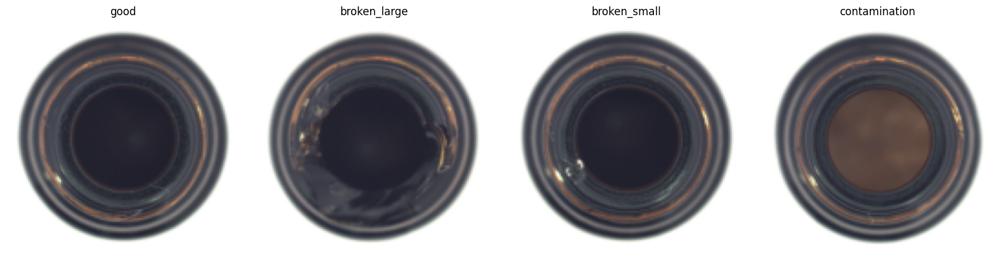

In [ ]:
show_dataset_images(test_dataset)

Funzione di test per calcolare le metriche di valutazione

In [ ]:
def test_ganomaly(model, test_loader, device):
  model.eval()
  all_labels = []
  all_scores = []
  alpha = 0.5 # Parametro per calcolo anomaly score
  with torch.no_grad():
    for data in test_loader:
      # Carico l'immagine e la sua etichetta
      x = data['image'].to(device)
      labels = data['label'].numpy()

      z, x_hat, z_hat, disc_real, disc_fake = model(x) # Invio l'immagine alla rete

      # Anomaly score -> combinazione dell'errore L1 nello spazio immagine e nello spazio latente
      # Con alpha = 0 -> formula del paper originale (differenza tra spazi latenti)
      score = alpha * torch.mean(torch.abs(x - x_hat), dim=[1,2,3]) + (1 - alpha) * torch.mean(torch.abs(z - z_hat), dim=[1,2,3])
      all_scores.extend(score.cpu().numpy())
      all_labels.extend(labels)

  all_scores = np.array(all_scores)
  all_labels = np.array(all_labels)

  # Predizioni: anomalo se score > threshold
  threshold = 0.065
  pred_labels = (all_scores > threshold).astype(int)

  # Calcolo metriche
  roc_auc = roc_auc_score(all_labels, all_scores)
  pr_auc = average_precision_score(all_labels, all_scores)
  precision = precision_score(all_labels, pred_labels)
  recall = recall_score(all_labels, pred_labels)
  f1 = f1_score(all_labels, pred_labels)

  # Istogramma degli Anomaly Score
  plt.figure(figsize=(10, 6))
  bins = np.linspace(min(all_scores), max(all_scores), 50)

  plt.hist(all_scores[all_labels == 0], bins=bins, alpha=0.6, label="Normal (0)", color='blue', edgecolor='black')
  plt.hist(all_scores[all_labels == 1], bins=bins, alpha=0.6, label="Anomaly (1)", color='coral', edgecolor='black')
  plt.axvline(threshold, color='black', linestyle='--', label=f'Threshold = {threshold:.3f}', linewidth=2)

  plt.xlabel("Anomaly Score")
  plt.ylabel("Frequency")
  plt.title("Distribuzione Anomaly Score")
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.5)
  plt.tight_layout()
  plt.show()

  # Istogramma per le metriche di valutazione
  metrics = {
    'ROC-AUC': roc_auc,
    'PR-AUC': pr_auc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
  }

  plt.figure(figsize=(10, 6))
  bars = plt.bar(metrics.keys(), metrics.values(), color=['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#9467bd'])
  plt.ylim([0, 1.1])
  plt.ylabel("Punteggio")
  plt.title("Metriche di Valutazione")

  for i, (k, v) in enumerate(metrics.items()):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', va='bottom', fontweight='bold')

  plt.tight_layout()
  plt.show()

Chiamata funzione di test

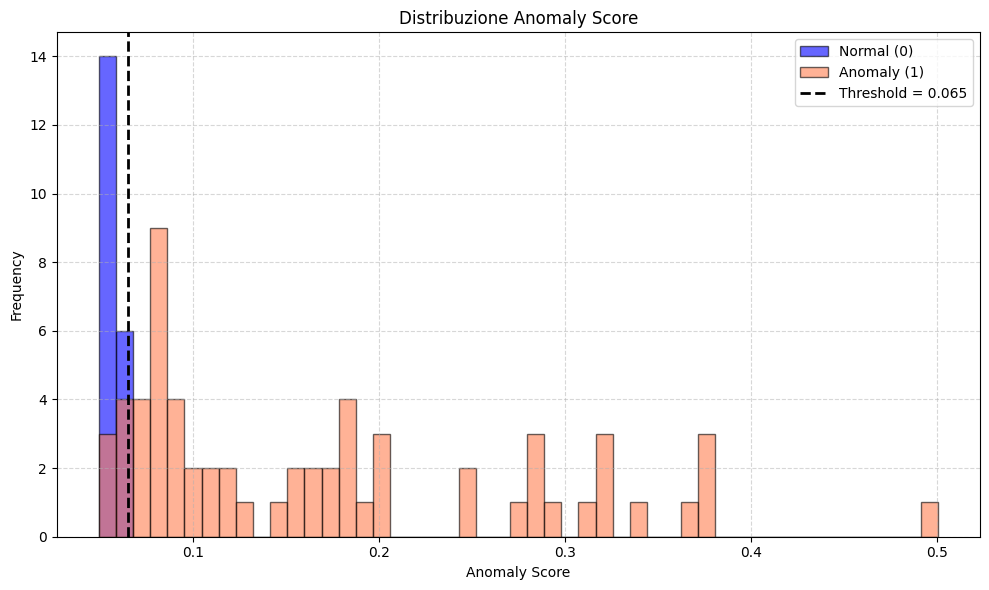

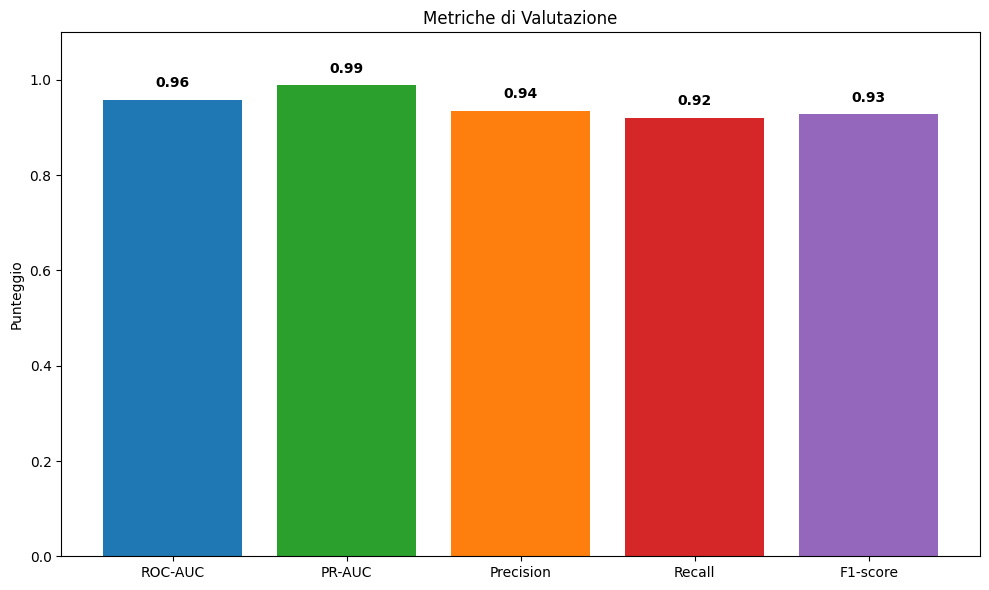

In [ ]:
test_ganomaly(model, test_loader, device)

Metodo per visualizzare lo spazio latente su tensorboard

In [ ]:
def log_latent_space_tensorboard(model, dataloader, device, tag='latent', log_dir='/content/drive/My Drive/Colab Notebooks/Computer vision/runs/latent_space'):
    def denormalize(img_tensor):
        # Metodo che 'denormalizza' l'immagine in modo da non avere errori di visualizzazione
        return img_tensor * 0.5 + 0.5

    model.eval()
    embeddings = []
    labels = []
    images = []

    with torch.no_grad():
        for data in dataloader:
            # Carico le immagini e le rispettive etichette
            x = data['image'].to(device)
            y = data['label']
            # Salvo gli spazi latenti che il modello ottinene
            z, _, z_hat, _, _ = model(x)
            latent = z_hat

            # Assicuro che il tensore latente sia [B, D]
            if latent.dim() > 2:
                latent = F.adaptive_avg_pool2d(latent, 1)  # [B, C, 1, 1]
                latent = latent.view(latent.size(0), -1)   # [B, C]

            embeddings.append(latent.cpu())
            labels.extend(y.cpu().numpy())
            images.append(denormalize(x.cpu()))  # Denormalizzazione

    embeddings = torch.cat(embeddings)
    images = torch.cat(images)

    writer = SummaryWriter(log_dir=log_dir)
    writer.add_embedding(embeddings, metadata=labels, label_img=images, tag=tag)
    writer.close()

In [ ]:
log_latent_space_tensorboard(model, test_loader, device)

In [ ]:
%load_ext tensorboard
%tensorboard --logdir="/content/drive/My Drive/Colab Notebooks/Computer vision/runs/latent_space"

Output hidden; open in https://colab.research.google.com to view.